# Notebook 9 - Held-out evaluation and cross-route conclusions

**Question:** after fixing the research choices, how do the same procedures perform on the reserved dates?

This closes the **exploratory modeling** sequence for Routes 7, 3, 11, and 711. It does not turn inferred schedule links into independently verified ground truth.

## Before running
Put the four original route Excel workbooks and `RTS_GTFS_Spring2023.zip` beside this notebook. No previous notebook, prepared CSV, or external Python helper is required. Executed results and graphs are included.

| Step | Purpose |
|---|---|
| 1 | Record the model choices and frozen rules before scoring |
| 2 | Reproduce each route's existing preparation and show coverage |
| 3 | Create a label-review ledger and identify unresolved checks |
| 4 | Refit on eligible development labels and score the reserved dates |
| 5 | Compare errors, graph the results, and synthesize conclusions |

## What is and is not final?
The **dates are held out from the earlier modeling** and the procedure choices below are fixed before their evaluation. However, schedule assignments remain provisional; a direct scheduled-trip identifier or independently confirmed historical matching evidence is unavailable. We run a **provisional held-out evaluation**, not a verified operational accuracy claim.

Automated checks and an auditable review sample are included. Independent label confirmation remains an open research task. We do not claim that sampling verifies all records, and do not mark manual checks complete automatically.

**No new model search:** all four route notebooks selected the fixed random forest by training-date fold MAE. We carry that choice forward even where a median or regression had lower validation MAE. Baselines are the published timetable and a median fitted on development labels. We do not select a winner or change filters using held-out errors.

**Final project order:** Notebook 8 contains the pooled-model extension; Notebook 9 is this closing synthesis. The evaluation outcomes were already inspected in earlier project runs. Reordering the notebooks does not create a new untouched test.

**Project status:** the exploratory undergraduate analysis is complete. We retain inferred matches as an explicit working assumption. Independent confirmation is documented as a limitation, not silently claimed complete. No additional route, model, or data collection is required to present the project in this scope.

## 1. Reproduce the previously recorded analysis plan

The forest settings are identical to those already tested. Feature groups remain route-specific. Development includes each earlier training and validation period; refitting on both is appropriate once choices are frozen. No feature selection, hyperparameter tuning, or outlier trimming is performed on the held-out dates.

This cell saves a small `Route_Final_Evaluation_Plan.json` in the current folder. It records the choices before scoring. Rerunning with the same plan is reproducible; a different plan is rejected rather than silently replacing it. Re-reading these results is not another independent test.

This reproduces the plan already used in the project. Its original timing is historical; rerunning it after the outcomes are known is reproducibility, not a fresh pre-registration or test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile, json, hashlib
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROUTES = {
    "7": {"file":"RTS_Route7_March2023.xlsx", "development_days":13, "expected_development_labels":304,
          "features":["direction_id","scheduled_hour","weekday"]},
    "3": {"file":"RTS_Route3_Spring2023.xlsx", "development_days":13, "expected_development_labels":196,
          "features":["direction_id","scheduled_hour","weekday"]},
    "11": {"file":"RTS_Route11_Spring2023.xlsx", "development_days":13, "expected_development_labels":781,
           "features":["direction_id","scheduled_hour","weekday","stop_id"]},
    "711": {"file":"RTS_Route711_Spring2023.xlsx", "development_days":6, "expected_development_labels":110,
            "features":["direction_id","scheduled_hour"]}
}
FOREST_SETTINGS = {"n_estimators":300,"max_depth":4,"min_samples_leaf":10,"random_state":42,"n_jobs":1}
freeze_plan = {"routes":ROUTES, "forest":FOREST_SETTINGS, "primary_selection":"previous training-date fold MAE",
    "primary_method":"Frozen random forest", "baselines":["Published schedule","Development median"],
    "matching_window_minutes":20, "remove_extreme_delays":False,
    "label_status":"provisional; independent schedule-link confirmation incomplete",
    "target":"actual arrival minus scheduled arrival, minutes", "test_dates_used_for_tuning":False}
plan_path = Path("Route_Final_Evaluation_Plan.json")
if plan_path.exists():
    assert json.loads(plan_path.read_text(encoding="utf-8")) == freeze_plan, "A different frozen plan already exists. Do not overwrite it after viewing test results."
else:
    plan_path.write_text(json.dumps(freeze_plan,indent=2),encoding="utf-8")
plan_hash = hashlib.sha256(json.dumps(freeze_plan,sort_keys=True).encode()).hexdigest()
source_hashes = {file:hashlib.sha256(Path(file).read_bytes()).hexdigest()
                 for file in [*[r["file"] for r in ROUTES.values()],"RTS_GTFS_Spring2023.zip"]}
print("Frozen plan SHA256:",plan_hash)
display(pd.DataFrame([{"route":r,"chosen_procedure":"Fixed random forest","development_labels_expected":s["expected_development_labels"],
    "features":", ".join(s["features"])} for r,s in ROUTES.items()]))

Frozen plan SHA256: 4c412b695ef6dff0ae38973cd7bbaa0f8a9bef9ca455005c84ec94f2143536ac


,route,chosen_procedure,development_labels_expected,features
0,7,Fixed random forest,304,"direction_id, scheduled_hour, weekday"
1,3,Fixed random forest,196,"direction_id, scheduled_hour, weekday"
2,11,Fixed random forest,781,"direction_id, scheduled_hour, weekday, stop_id"
3,711,Fixed random forest,110,"direction_id, scheduled_hour"


## 2. Reuse the existing preparation rules

The support functions below reproduce the route notebooks: field flags, terminal exclusions, schedule calendars, source-order evidence, and other-timepoint corroboration. Routes 7/3/11 use consistent sequence positions. Route 711 preserves its distinct recorded numbering and aligns physical stop order.

For Route 7 the target remains Health Department only; Routes 3/711 retain their two directional Walmart timepoints; Route 11 includes its published intermediate stops. These scopes are not expanded during final evaluation.

**Read the counts and examples first.** The function definitions are technical support; they do not fit models or choose rules from prediction errors. Automated assertions require the development sample sizes to match the earlier notebooks before scoring proceeds.

In [2]:
def read_gtfs(name):
    with zipfile.ZipFile('RTS_GTFS_Spring2023.zip') as archive:
        table = pd.read_csv(archive.open(name), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

def load_route(route, settings):
    """Reproduce the earlier route-specific preparation without using model errors."""
    raw = pd.read_excel(settings['file'], engine='openpyxl')
    data = raw.drop_duplicates().copy()
    data['source_row'] = data.index
    data['bus_id'] = data.Bus.astype('string')
    data['stop_id'] = data['Stop ID'].astype('string').str.replace(r'\.0$', '', regex=True)
    data['stop_sequence'] = pd.to_numeric(data['Stop Seq ID'], errors='coerce')
    data['service_date'] = pd.to_datetime(data.Date, errors='coerce').dt.normalize()
    clock = pd.to_timedelta(data.Arrive.astype(str), errors='coerce')
    clock = clock.where(clock.ge(pd.Timedelta(0)) & clock.lt(pd.Timedelta(days=1)))
    data['actual_arrival'] = data.service_date + clock
    bad = (data[['bus_id','stop_id','stop_sequence','actual_arrival']].isna().any(axis=1)
           | data.stop_sequence.lt(0) | data.stop_sequence.mod(1).ne(0)
           | data.stop_sequence.eq(999) | data.stop_id.eq('9999'))
    repeated = data.duplicated(['bus_id','service_date','stop_id','actual_arrival'], keep=False)
    tied = data.duplicated(['bus_id','service_date','actual_arrival'], keep=False)
    data['bad_fields'], data['needs_review'] = bad, bad | repeated | tied
    dates = sorted(data.service_date.dropna().unique())
    development_dates = dates[:settings['development_days']]
    test_dates = dates[settings['development_days']:]
    assert development_dates and test_dates
    data = data.sort_values(['bus_id','service_date','source_row']).copy()
    group = data.groupby(['bus_id','service_date'], sort=False)
    if route == '711':
        valid_sequence = data.stop_sequence.where(~data.bad_fields)
        previous = valid_sequence.groupby([data.bus_id,data.service_date]).ffill().groupby([data.bus_id,data.service_date]).shift()
        reset = valid_sequence.lt(previous)
    else:
        reset = data.stop_sequence.lt(group.stop_sequence.shift())
    data['new_block'] = group.cumcount().eq(0) | reset
    data['block_number'] = data.groupby(['bus_id','service_date']).new_block.cumsum()
    data['source_block_id'] = data.bus_id.astype(str)+'|'+data.service_date.dt.strftime('%Y-%m-%d')+'|'+data.block_number.astype(str)
    blocks = dict(tuple(data.groupby('source_block_id', sort=False)))
    route_trips = gtfs_trips.loc[gtfs_trips.route_id.eq(route)]
    route_times = route_trips.merge(gtfs_stop_times, on='trip_id', validate='one_to_many')
    route_times['scheduled_sequence'] = pd.to_numeric(route_times.stop_sequence)
    patterns = {tid:list(zip(g.sort_values('scheduled_sequence').scheduled_sequence, g.sort_values('scheduled_sequence').stop_id))
                for tid,g in route_times.groupby('trip_id')}
    last_sequence = {tid:max(seq for seq,stop in pattern) for tid,pattern in patterns.items()}
    published = route_times.loc[route_times.arrival_time.ne('')].copy()
    days = []
    for day in dates:
        day = pd.Timestamp(day)
        stamp = day.strftime('%Y%m%d')
        active = set(gtfs_calendar.loc[gtfs_calendar.start_date.le(stamp) & gtfs_calendar.end_date.ge(stamp)
            & gtfs_calendar[day.day_name().lower()].eq('1'), 'service_id'])
        for change in gtfs_exceptions.loc[gtfs_exceptions.date.eq(stamp)].itertuples(index=False):
            if change.exception_type == '1': active.add(change.service_id)
            elif change.exception_type == '2': active.discard(change.service_id)
        portion = published.loc[published.service_id.isin(active)].copy()
        portion['service_date'] = day
        portion['scheduled_arrival'] = day + pd.to_timedelta(portion.arrival_time)
        days.append(portion)
    schedule = pd.concat(days, ignore_index=True)
    schedule['intermediate'] = schedule.scheduled_sequence.gt(0) & schedule.scheduled_sequence.lt(schedule.trip_id.map(last_sequence))
    date_trips = dict(tuple(schedule.groupby('service_date')))
    timed_ids = set(schedule.stop_id)
    audit_rows = []

    if route == '711':
        target_ids = set(schedule.loc[schedule.intermediate, 'stop_id'])
        targets = data.loc[data.stop_id.isin(target_ids)].copy()
        for visit in targets.itertuples():
            block = blocks[visit.source_block_id]
            ordinary = block.loc[~block.bad_fields]
            values = ordinary.stop_id.tolist()
            observed = [v for i,v in enumerate(values) if i == 0 or v != values[i-1]]
            status, chosen, n_anchors, n_strict = 'target_flagged_or_inconsistent_block', None, 0, 0
            if not visit.needs_review and ordinary.actual_arrival.is_monotonic_increasing and len([s for s in observed if s != visit.stop_id]) >= 5:
                timetable = date_trips[visit.service_date]
                eligible = []
                for tid in timetable.trip_id.unique():
                    expected = [stop for seq,stop in patterns[tid]]
                    if len(set(expected)) != len(expected): continue
                    positions = {stop:i for i,stop in enumerate(expected)}
                    if any(s not in positions for s in observed): continue
                    order = [positions[s] for s in observed]
                    if all(b > a for a,b in zip(order,order[1:])): eligible.append(tid)
                proposed = timetable.loc[timetable.trip_id.isin(eligible) & timetable.stop_id.eq(visit.stop_id) & timetable.intermediate]
                proposed = proposed.loc[(proposed.scheduled_arrival-visit.actual_arrival).dt.total_seconds().abs().le(20*60)]
                anchors = ordinary.loc[ordinary.stop_id.isin(timed_ids) & ordinary.stop_id.ne(visit.stop_id)].copy()
                anchors = anchors.loc[anchors.groupby('stop_id').actual_arrival.transform('nunique').eq(1)].drop_duplicates(['stop_id','actual_arrival'])
                def supported(a):
                    if a.empty: return []
                    links = a.merge(timetable.loc[timetable.trip_id.isin(eligible), ['trip_id','stop_id','scheduled_arrival']], on='stop_id')
                    links['near'] = (links.actual_arrival-links.scheduled_arrival).dt.total_seconds().abs().le(20*60)
                    evidence = links.groupby('trip_id').agg(covered=('stop_id','nunique'), all_near=('near','all'))
                    return evidence.index[evidence.covered.eq(a.stop_id.nunique()) & evidence.all_near].tolist()
                ids, strict_ids = supported(anchors), supported(anchors.loc[~anchors.needs_review])
                n_anchors, n_strict = len(anchors), len(anchors.loc[~anchors.needs_review])
                status = 'ambiguous_missing_or_unsupported_schedule_assignment'
                if len(proposed) == 1 and len(ids) == 1 and ids[0] == proposed.trip_id.iloc[0]:
                    chosen = proposed.iloc[0]
                    status = 'provisional_unflagged_anchor_support' if strict_ids == ids else 'provisional_terminal_dependent'
            audit_rows.append(dict(source_row=visit.source_row, status=status, other_timed_anchors=n_anchors,
                other_unflagged_anchors=n_strict, trip_id=None if chosen is None else chosen.trip_id,
                direction_id=None if chosen is None else chosen.direction_id,
                scheduled_sequence=np.nan if chosen is None else chosen.scheduled_sequence,
                scheduled_arrival=pd.NaT if chosen is None else chosen.scheduled_arrival))
        audit = pd.DataFrame(audit_rows)
        clean = targets.merge(audit,on='source_row',validate='one_to_one')
        clean = clean.loc[clean.status.str.startswith('provisional')].copy()
        conflict = clean.duplicated(['service_date','trip_id','stop_id'],keep=False)
        audit.loc[audit.source_row.isin(clean.loc[conflict,'source_row']), 'status'] = 'competing_scheduled_visit_claim'
        clean = clean.loc[~conflict].copy()
        timed_records = data.loc[data.stop_id.isin(timed_ids)].copy()
    else:
        keys = ['service_date','stop_id','stop_sequence']
        timetable = schedule.rename(columns={'stop_sequence':'gtfs_sequence_text','scheduled_sequence':'stop_sequence'})
        observations = data.loc[~data.needs_review]
        candidates = observations.merge(timetable,on=keys,how='inner')
        candidates = candidates.loc[(candidates.actual_arrival-candidates.scheduled_arrival).dt.total_seconds().abs().le(20*60)].copy()
        counts = candidates.groupby('source_row').source_row.transform('size')
        matched = candidates.loc[counts.eq(1)].copy()
        conflict = matched.duplicated(['service_date','trip_id','stop_sequence'],keep=False)
        matched = matched.loc[~conflict].copy()
        targets = matched.loc[matched.intermediate].copy()
        if route == '7': targets = targets.loc[targets.stop_id.eq('107')].copy()
        timed_keys = timetable[['stop_id','stop_sequence']].drop_duplicates()
        for visit in targets.itertuples():
            block = blocks[visit.source_block_id]
            ordinary = block.loc[block.stop_sequence.between(0,max(last_sequence.values())) & block.stop_id.ne('9999')]
            observed = list(dict.fromkeys(zip(ordinary.stop_sequence, ordinary.stop_id)))
            expected = dict(patterns[visit.trip_id])
            pattern_ok = all(expected.get(seq) == stop for seq,stop in observed)
            other_pattern = [(seq,stop) for seq,stop in observed if seq != visit.stop_sequence]
            anchors = block.merge(timed_keys,on=['stop_id','stop_sequence'],how='inner')
            anchors = anchors.loc[anchors.stop_sequence.ne(visit.stop_sequence) & anchors.actual_arrival.notna()].copy()
            anchors = anchors.loc[anchors.groupby('stop_sequence').actual_arrival.transform('nunique').eq(1)]
            anchors = anchors.drop_duplicates(['stop_sequence','stop_id','actual_arrival'])
            def supported(a):
                if a.empty or len(other_pattern) < 5: return []
                daily = timetable.loc[timetable.service_date.eq(visit.service_date)]
                eligible = [tid for tid in daily.trip_id.unique() if all(dict(patterns[tid]).get(seq)==stop for seq,stop in other_pattern)]
                links = a.merge(daily.loc[daily.trip_id.isin(eligible), ['trip_id','stop_id','stop_sequence','scheduled_arrival']],on=['stop_id','stop_sequence'])
                links['near'] = (links.actual_arrival-links.scheduled_arrival).dt.total_seconds().abs().le(20*60)
                evidence = links.groupby('trip_id').agg(covered=('stop_sequence','nunique'), all_near=('near','all'))
                return evidence.index[evidence.covered.eq(a.stop_sequence.nunique()) & evidence.all_near].tolist()
            ids, strict_ids = supported(anchors), supported(anchors.loc[~anchors.needs_review])
            good = pattern_ok and block.actual_arrival.is_monotonic_increasing and ids == [visit.trip_id]
            status = 'unsupported_pattern_time_or_other_anchor_assignment'
            if good: status = 'provisional_unflagged_anchor_support' if strict_ids == ids else 'provisional_terminal_dependent'
            audit_rows.append(dict(source_row=visit.source_row,status=status,other_timed_anchors=len(anchors),other_unflagged_anchors=len(anchors.loc[~anchors.needs_review])))
        audit = pd.DataFrame(audit_rows)
        clean = targets.merge(audit,on='source_row',validate='one_to_one')
        clean = clean.loc[clean.status.str.startswith('provisional')].copy()
        clean['scheduled_sequence'] = clean.stop_sequence
        timed_records = data.merge(timetable[keys].drop_duplicates(),on=keys,validate='many_to_one')

    clean['delay_minutes'] = (clean.actual_arrival-clean.scheduled_arrival).dt.total_seconds()/60
    clean['scheduled_hour'] = clean.scheduled_arrival.dt.hour
    clean['weekday'] = clean.service_date.dt.day_name()
    clean['direction_id'] = clean.direction_id.astype(str)
    clean['route'] = route
    clean['evaluation_split'] = np.where(clean.service_date.isin(development_dates),'development','final_test')
    held = timed_records.loc[~timed_records.source_row.isin(clean.source_row)].copy()
    held = held.merge(audit[['source_row','status']],on='source_row',how='left',validate='one_to_one')
    held['hold_reason'] = held.status.fillna('terminal, flagged, ambiguous, unmatched, or outside frozen target scope')
    development = clean.loc[clean.evaluation_split.eq('development')].copy()
    test = clean.loc[clean.evaluation_split.eq('final_test')].copy()
    assert len(development) == settings['expected_development_labels'], (route,len(development))
    assert development.service_date.max() < test.service_date.min()
    assert clean.source_row.is_unique
    assert not clean.duplicated(['service_date','trip_id','stop_id']).any()
    assert np.allclose(clean.delay_minutes,(clean.actual_arrival-clean.scheduled_arrival).dt.total_seconds()/60)
    assert len(clean)+len(held)==len(timed_records)
    return dict(raw=raw,data=data,clean=clean,development=development,test=test,held=held,audit=audit,
                development_dates=development_dates,test_dates=test_dates,timed_records=timed_records)


In [3]:
gtfs_trips = read_gtfs("trips.txt")
gtfs_stop_times = read_gtfs("stop_times.txt")
gtfs_calendar = read_gtfs("calendar.txt")
gtfs_exceptions = read_gtfs("calendar_dates.txt")
route_data = {}
coverage_rows = []
for route, settings in ROUTES.items():
    result = load_route(route,settings)
    route_data[route] = result
    for split, label in [("development","Development"),("final_test","Held-out")]:
        part = result["clean"].loc[result["clean"].evaluation_split.eq(split)]
        dates = result["development_dates"] if split == "development" else result["test_dates"]
        raw_part = result["data"].loc[result["data"].service_date.isin(dates)]
        timed_part = result["timed_records"].loc[result["timed_records"].service_date.isin(dates)]
        coverage_rows.append({"route":route,"period":label,"dates":", ".join(str(pd.Timestamp(d).date()) for d in dates),
            "raw_visits":len(raw_part),"recorded_timepoint_visits":len(timed_part),"retained_labels":len(part),
            "timepoint_records_held":len(timed_part)-len(part),"modeled_stops":", ".join(sorted(part.stop_id.unique()))})
coverage = pd.DataFrame(coverage_rows)
display(coverage)
print("Rows held for review are retained in route_data[route]['held']; raw data are not overwritten.")

Rows held for review are retained in route_data[route]['held']; raw data are not overwritten.


,route,period,dates,raw_visits,recorded_timepoint_visits,retained_labels,timepoint_records_held,modeled_stops
0,7,Development,"2023-03-01, 2023-03-02, 2023-03-03, 2023-03-06, 2023-03-07, 2023-03-08, 2023-03-09, 2023-03-10, 2023-03-13, 2023-03-14, 2023-03-15, 2023-03-16, 2023-03-17",11280,961,304,657,107
1,7,Held-out,"2023-03-20, 2023-03-21, 2023-03-22, 2023-03-23",3405,291,93,198,107
2,3,Development,"2023-03-01, 2023-03-02, 2023-03-03, 2023-03-06, 2023-03-07, 2023-03-08, 2023-03-09, 2023-03-10, 2023-03-13, 2023-03-14, 2023-03-15, 2023-03-16, 2023-03-17",6562,673,196,477,"1234, 1235"
3,3,Held-out,"2023-03-20, 2023-03-21, 2023-03-22, 2023-03-23",2080,224,64,160,"1234, 1235"
4,11,Development,"2023-03-01, 2023-03-02, 2023-03-03, 2023-03-06, 2023-03-07, 2023-03-08, 2023-03-09, 2023-03-10, 2023-03-13, 2023-03-14, 2023-03-15, 2023-03-16, 2023-03-17",17850,1958,781,1177,"107, 1234, 1235"
5,11,Held-out,"2023-03-20, 2023-03-21, 2023-03-22, 2023-03-23",5515,604,244,360,"107, 1234, 1235"
6,711,Development,"2023-03-04, 2023-03-05, 2023-03-11, 2023-03-12, 2023-03-17, 2023-03-18",3697,338,110,228,"1234, 1235"
7,711,Held-out,2023-03-19,379,29,9,20,"1234, 1235"


## 3. Label review: what checks passed and what remains open?

The ledger samples the earliest development label per stop/direction, two extreme development delays, and two held-out labels chosen by source-row order, not their prediction errors. It records proposed scheduled trips, times, sequence positions, and other-anchor support. Review neighboring raw stops through `route_data[route]['data']` using the source block ID.

Automated pattern/order/anchor checks are necessary evidence, not independent confirmation. Terminal-dependent support is weaker; terminal arrival does not necessarily mean actual departure. **Every manual review status starts as unconfirmed.** Change it only when evidence and reviewer notes are documented.

The frozen 20-minute matching and other-anchor rules can exclude severe/ambiguous cases. Scores apply to retained labels and can be optimistic for overall service. The coverage table makes this selection visible. We do not delete unusual retained test delays or adjust rules to improve held-out scores.

In [4]:
review_parts, support_rows = [], []
for route, result in route_data.items():
    dev, test = result["development"], result["test"]
    first = dev.sort_values("source_row").groupby(["stop_id","direction_id"],as_index=False).head(1)
    extreme = dev.loc[dev.delay_minutes.abs().nlargest(2).index]
    fixed_test = test.sort_values("source_row").head(2)
    sample = pd.concat([first,extreme,fixed_test]).drop_duplicates("source_row").copy()
    cols = ["route","source_row","source_block_id","evaluation_split","service_date","bus_id","stop_id","stop_sequence",
            "scheduled_sequence","trip_id","scheduled_arrival","actual_arrival","delay_minutes","status","other_unflagged_anchors"]
    sample = sample[cols]
    sample["independent_review"] = "unconfirmed: requires independent schedule-link evidence"
    sample["reviewer_notes"] = ""
    review_parts.append(sample)
    for split,g in result["clean"].groupby("evaluation_split"):
        support_rows.append({"route":route,"period":split,"labels":len(g),
            "unflagged_other_anchor_support":int(g.status.eq("provisional_unflagged_anchor_support").sum()),
            "terminal_dependent_support":int(g.status.eq("provisional_terminal_dependent").sum()),
            "independently_confirmed_labels":0})
review_ledger = pd.concat(review_parts,ignore_index=True)
support_summary = pd.DataFrame(support_rows)
display(support_summary)
display(review_ledger[["route","source_row","evaluation_split","stop_id","trip_id","scheduled_arrival","actual_arrival","status","independent_review"]])
print("Independent confirmation remains incomplete; following scores are provisional held-out results.")

Independent confirmation remains incomplete; following scores are provisional held-out results.


,route,period,labels,unflagged_other_anchor_support,terminal_dependent_support,independently_confirmed_labels
0,7,development,304,12,292,0
1,7,final_test,93,4,89,0
2,3,development,196,100,96,0
3,3,final_test,64,36,28,0
4,11,development,781,428,353,0
5,11,final_test,244,136,108,0
6,711,development,110,13,97,0
7,711,final_test,9,1,8,0


,route,source_row,evaluation_split,stop_id,trip_id,scheduled_arrival,actual_arrival,status,independent_review
0,7,13,development,107,4059089,2023-03-01 06:08:00,2023-03-01 06:13:20,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
1,7,50,development,107,4059101,2023-03-01 06:40:00,2023-03-01 06:41:12,provisional_terminal_dependent,unconfirmed: requires independent schedule-link evidence
2,7,10657,development,107,4059093,2023-03-17 10:08:00,2023-03-17 10:22:33,provisional_terminal_dependent,unconfirmed: requires independent schedule-link evidence
3,7,10401,development,107,4059089,2023-03-17 06:08:00,2023-03-17 06:20:31,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
4,7,11293,final_test,107,4059089,2023-03-20 06:08:00,2023-03-20 06:09:57,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
5,7,11330,final_test,107,4059101,2023-03-20 06:40:00,2023-03-20 06:42:00,provisional_terminal_dependent,unconfirmed: requires independent schedule-link evidence
6,3,24,development,1235,1003001,2023-03-01 09:47:00,2023-03-01 09:46:07,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
7,3,41,development,1234,1003002,2023-03-01 10:08:00,2023-03-01 10:10:06,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
8,3,6412,development,1234,1003012,2023-03-17 15:08:00,2023-03-17 15:19:38,provisional_unflagged_anchor_support,unconfirmed: requires independent schedule-link evidence
9,3,6267,development,1235,1003007,2023-03-17 12:47:00,2023-03-17 12:57:26,provisional_terminal_dependent,unconfirmed: requires independent schedule-link evidence


## 4. Refit the frozen procedures and evaluate reserved dates

Fit the fixed forest on all eligible development labels. Fit its category encoder there too. Recompute the median using only development delays. The timetable predicts zero delay.

All three procedures predict the same retained held-out arrivals for a route. We record errors by route and date, with source IDs for tracing examples. We do not add a new model, tune parameters, choose a new predictor subset, or select another method after reading this table.

MAE is average absolute error in minutes; RMSE puts more weight on large misses. R² compares squared error with the held-out sample mean, which is unavailable in advance. Also report percentages within 1/2/5 minutes to describe practical misses. These thresholds are descriptive, not selection rules.

In [5]:
def frozen_forest(features):
    categories = [c for c in features if c != "scheduled_hour"]
    prep = ColumnTransformer([("categories",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categories),
                              ("hour","passthrough",["scheduled_hour"])])
    return Pipeline([("prepare",prep),("model",RandomForestRegressor(**FOREST_SETTINGS))])

score_rows, prediction_parts, daily_rows, input_support_rows = [], [], [], []
fitted_models = {}
for route, settings in ROUTES.items():
    dev,test = route_data[route]["development"],route_data[route]["test"]
    features = settings["features"]
    model = frozen_forest(features).fit(dev[features],dev.delay_minutes)
    fitted_models[route] = model
    predictions = {"Published schedule":np.zeros(len(test)),
        "Development median":np.repeat(dev.delay_minutes.median(),len(test)),
        "Frozen random forest":model.predict(test[features])}
    known = dev[features].drop_duplicates().assign(previously_observed=True)
    support = test[features].merge(known,on=features,how="left",validate="many_to_one").previously_observed.fillna(False)
    input_support_rows.append({"route":route,"held_out_arrivals":len(test),"previously_observed_input_combinations":int(support.sum()),
                               "new_input_combinations":int((~support).sum())})
    for method,pred in predictions.items():
        errors = pred-test.delay_minutes.to_numpy()
        score_rows.append({"route":route,"method":method,"development_labels":len(dev),"test_labels":len(test),
            "test_days":test.service_date.nunique(),"MAE_minutes":np.abs(errors).mean(),
            "RMSE_minutes":np.sqrt(np.mean(errors**2)),"R2":r2_score(test.delay_minutes,pred),
            "within_1_minute_pct":100*np.mean(np.abs(errors)<=1),"within_2_minutes_pct":100*np.mean(np.abs(errors)<=2),
            "within_5_minutes_pct":100*np.mean(np.abs(errors)<=5),"label_status":"provisional"})
        part = test[["route","source_row","service_date","bus_id","stop_id","direction_id","scheduled_arrival","actual_arrival","delay_minutes"]].copy()
        part["method"] = method
        part["predicted_delay_minutes"] = pred
        part["predicted_arrival"] = part.scheduled_arrival+pd.to_timedelta(pred,unit="min")
        part["signed_error_minutes"] = errors
        part["absolute_error_minutes"] = np.abs(errors)
        prediction_parts.append(part)
        for day,g in part.groupby("service_date"):
            daily_rows.append({"route":route,"date":day,"method":method,"arrivals":len(g),"MAE_minutes":g.absolute_error_minutes.mean()})
test_results = pd.DataFrame(score_rows)
test_predictions = pd.concat(prediction_parts,ignore_index=True)
daily_results = pd.DataFrame(daily_rows)
input_support = pd.DataFrame(input_support_rows)
display(test_results.round(3))
display(input_support)
assert test_results.groupby("route").test_labels.nunique().eq(1).all()
assert all(hashlib.sha256(Path(f).read_bytes()).hexdigest()==h for f,h in source_hashes.items())
print("Original source hashes unchanged; identical test population used for all three methods per route.")

Original source hashes unchanged; identical test population used for all three methods per route.


,route,method,development_labels,test_labels,test_days,MAE_minutes,RMSE_minutes,R2,within_1_minute_pct,within_2_minutes_pct,within_5_minutes_pct,label_status
0,7,Published schedule,304,93,4,4.020,5.194,-1.432,21.505,38.710,63.441,provisional
1,7,Development median,304,93,4,2.706,3.637,-0.192,23.656,53.763,87.097,provisional
2,7,Frozen random forest,304,93,4,2.020,3.057,0.157,44.086,63.441,90.323,provisional
3,3,Published schedule,196,64,4,1.629,2.058,-0.221,40.625,65.625,100.000,provisional
4,3,Development median,196,64,4,1.632,1.918,-0.060,34.375,65.625,100.000,provisional
5,3,Frozen random forest,196,64,4,1.772,2.203,-0.399,37.500,57.812,100.000,provisional
6,11,Published schedule,781,244,4,1.799,2.438,-0.209,42.213,67.213,93.033,provisional
7,11,Development median,781,244,4,1.617,2.219,-0.001,47.131,72.131,96.311,provisional
8,11,Frozen random forest,781,244,4,1.440,1.801,0.341,38.934,75.820,98.361,provisional
9,711,Published schedule,110,9,1,3.215,4.260,-0.839,22.222,33.333,77.778,provisional


,route,held_out_arrivals,previously_observed_input_combinations,new_input_combinations
0,7,93,93,0
1,3,64,64,0
2,11,244,244,0
3,711,9,9,0


## 5. Cross-route comparison and graphs

Report each route against its own baseline. Route 711 has a different calendar period and only one reserved day, while the other routes use four later weekdays. Stop scopes, matching conventions, and eligible samples differ. This is not a controlled ranking of route difficulty.

The **macro** average gives each route equal weight. The **pooled** average gives each arrival equal weight and can be dominated by the largest sample. We show both and do not call either a system-wide RTS estimate.

Example predictions from each route; positive delay means late:


method,Development median,Frozen random forest,Published schedule,forest_MAE_reduction_pct,median_MAE_reduction_pct
route,,,,,
7,2.706,2.020,4.020,49.746,32.694
3,1.632,1.772,1.629,-8.770,-0.128
11,1.617,1.440,1.799,19.933,10.124
711,2.388,2.696,3.215,16.152,25.720


,equal_route_weight_MAE,equal_arrival_weight_MAE
method,,
Development median,2.085,1.883
Frozen random forest,1.982,1.651
Published schedule,2.666,2.307


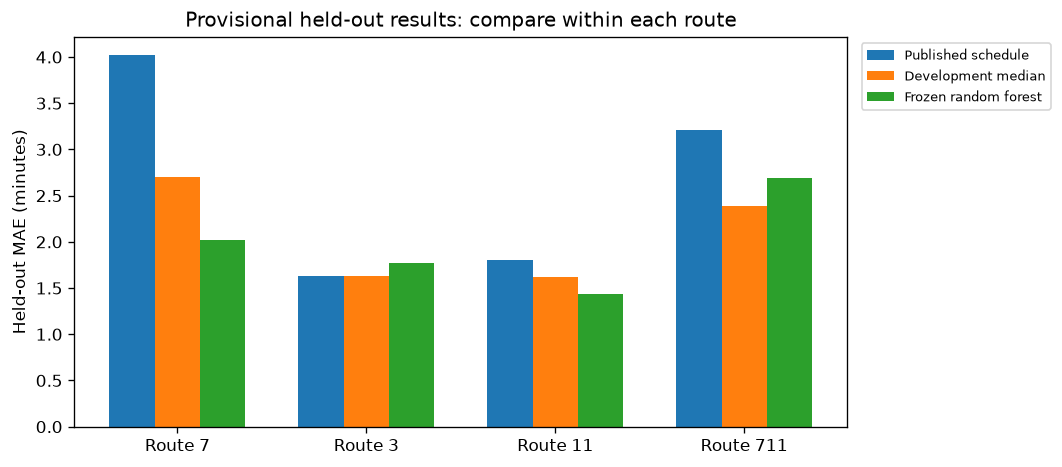

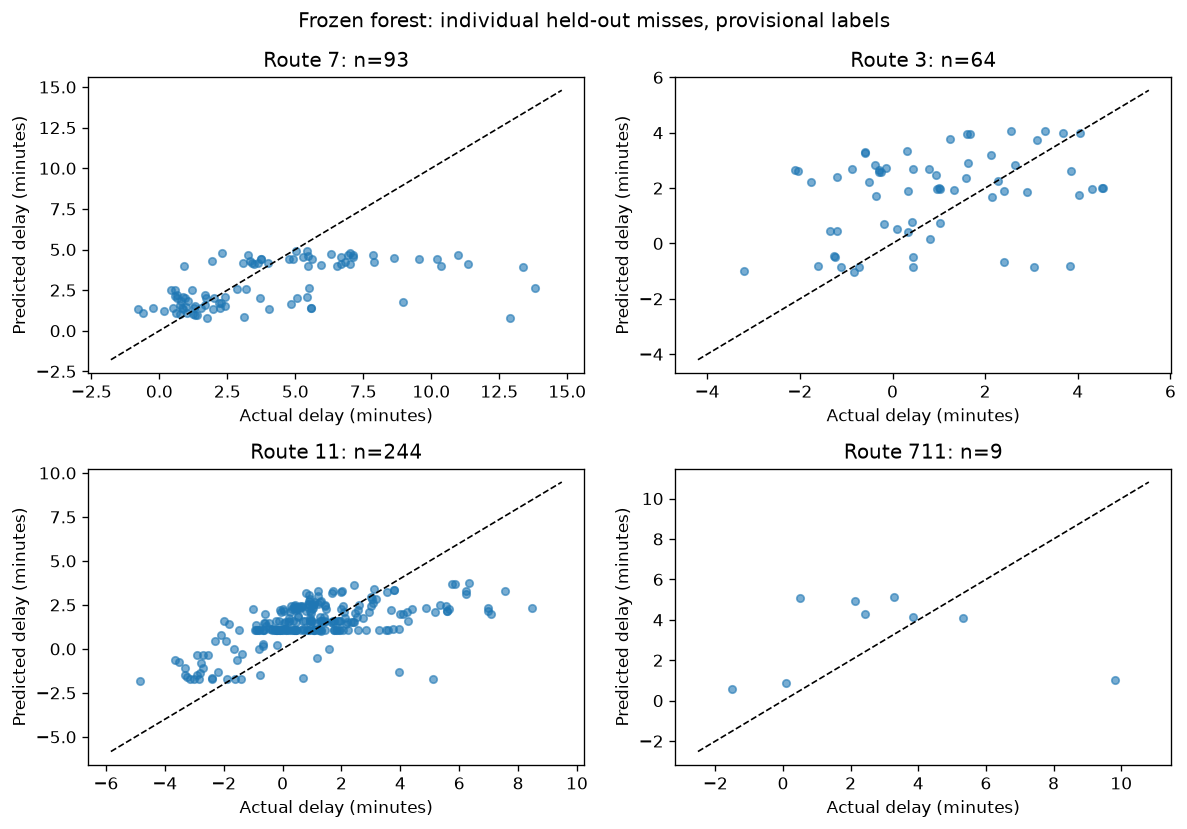

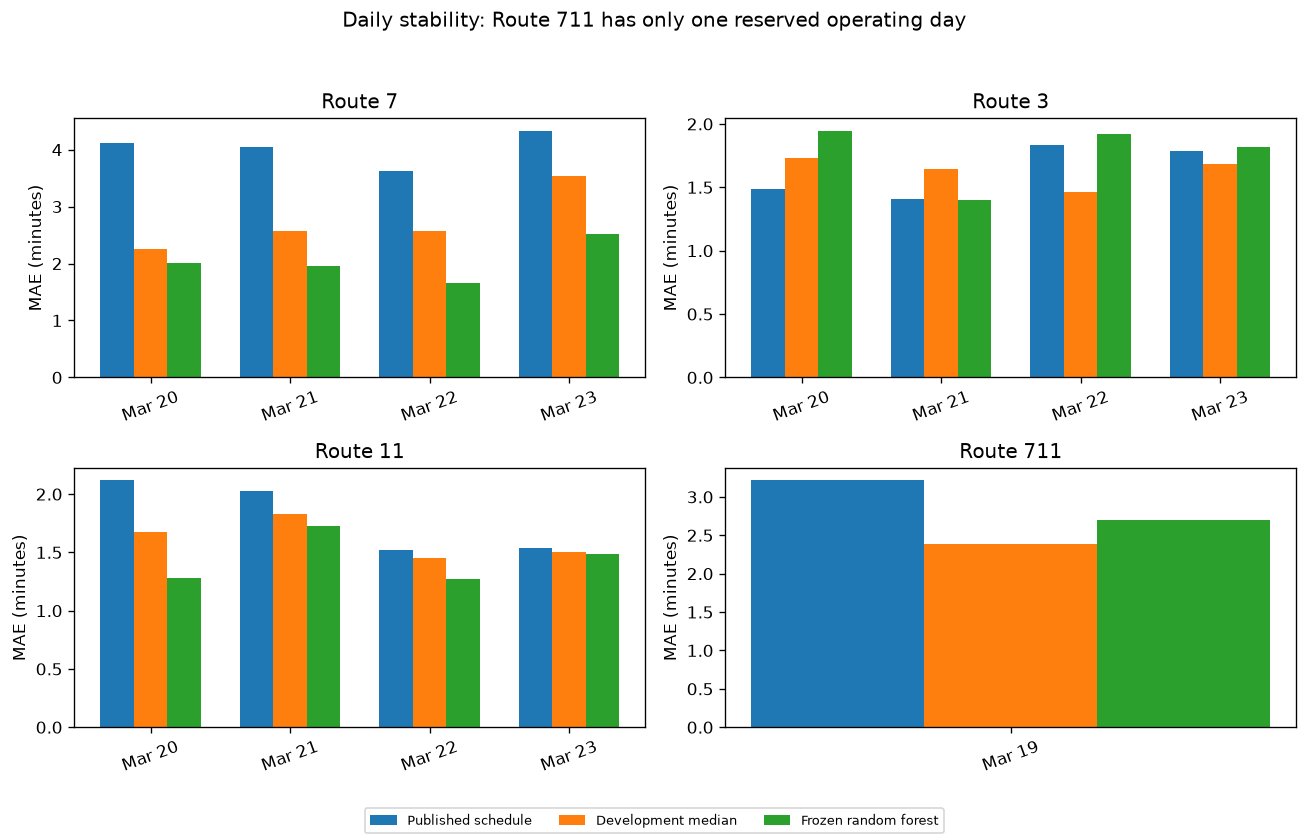

,route,source_row,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
186,7,12185,2023-03-21 06:08:00,2023-03-21 06:11:25,2023-03-21 06:12:10.363536204,0.756059
187,7,12233,2023-03-21 06:40:00,2023-03-21 06:40:40,2023-03-21 06:41:59.306701368,1.321778
188,7,12260,2023-03-21 07:08:00,2023-03-21 07:12:00,2023-03-21 07:12:10.363536204,0.172726
407,3,6586,2023-03-20 09:47:00,2023-03-20 09:48:02,2023-03-20 09:48:58.415140986,0.940252
408,3,6603,2023-03-20 10:08:00,2023-03-20 10:07:17,2023-03-20 10:07:09.531733710,0.124471
409,3,6651,2023-03-20 10:47:00,2023-03-20 10:48:19,2023-03-20 10:48:55.395741240,0.606596
959,11,19745,2023-03-21 05:40:00,2023-03-21 05:40:11,2023-03-21 05:41:03.491953674,0.874866
960,11,19768,2023-03-21 06:07:00,2023-03-21 06:09:26,2023-03-21 06:10:39.324367278,1.222073
961,11,19807,2023-03-21 06:40:00,2023-03-21 06:39:52,2023-03-21 06:41:04.359479286,1.205991
1221,711,3712,2023-03-19 12:07:00,2023-03-19 12:09:25,2023-03-19 12:11:16.936425570,1.865607


In [6]:
comparison = test_results.pivot(index="route",columns="method",values="MAE_minutes").reindex(ROUTES)
comparison["forest_MAE_reduction_pct"] = 100*(1-comparison["Frozen random forest"]/comparison["Published schedule"])
comparison["median_MAE_reduction_pct"] = 100*(1-comparison["Development median"]/comparison["Published schedule"])
display(comparison.round(3))
macro = test_results.groupby("method").agg(equal_route_weight_MAE=("MAE_minutes","mean"))
pooled = test_predictions.groupby("method").absolute_error_minutes.mean().rename("equal_arrival_weight_MAE")
aggregate = macro.join(pooled)
display(aggregate.round(3))

fig,ax = plt.subplots(figsize=(9,4))
methods = ["Published schedule","Development median","Frozen random forest"]
x=np.arange(len(comparison));width=.24
for j,method in enumerate(methods):ax.bar(x+(j-1)*width,comparison[method],width,label=method)
ax.set_xticks(x,[f"Route {r}" for r in comparison.index])
ax.set(ylabel="Held-out MAE (minutes)",title="Provisional held-out results: compare within each route")
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1.01,1))
fig.tight_layout();plt.show()

fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,route in zip(axes.flat,ROUTES):
    part=test_predictions.loc[test_predictions.route.eq(route)&test_predictions.method.eq("Frozen random forest")]
    ax.scatter(part.delay_minutes,part.predicted_delay_minutes,alpha=.6,s=20)
    low=min(part.delay_minutes.min(),part.predicted_delay_minutes.min())-1
    high=max(part.delay_minutes.max(),part.predicted_delay_minutes.max())+1
    ax.plot([low,high],[low,high],"k--",linewidth=1)
    ax.set(title=f"Route {route}: n={len(part)}",xlabel="Actual delay (minutes)",ylabel="Predicted delay (minutes)")
fig.suptitle("Frozen forest: individual held-out misses, provisional labels")
fig.tight_layout();plt.show()

fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,route in zip(axes.flat,ROUTES):
    part=daily_results.loc[daily_results.route.eq(route)].pivot(index="date",columns="method",values="MAE_minutes")
    x=np.arange(len(part))
    for j,method in enumerate(methods):ax.bar(x+(j-1)*.24,part[method],.24,label=method)
    ax.set_xticks(x,part.index.strftime("%b %d"),rotation=20)
    ax.set(title=f"Route {route}",ylabel="MAE (minutes)")
handles,labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",ncol=3,fontsize=8)
fig.suptitle("Daily stability: Route 711 has only one reserved operating day")
fig.tight_layout(rect=(0,.05,1,.95));plt.show()

print("Example predictions from each route; positive delay means late:")
display(test_predictions.loc[test_predictions.method.eq("Frozen random forest")].groupby("route",sort=False).head(3)
        [["route","source_row","scheduled_arrival","actual_arrival","predicted_arrival","absolute_error_minutes"]])

## 6. Read prediction accuracy and improvement correctly

**Accuracy here means the percentage of predictions within ±2 minutes of actual arrival.** It is not classification accuracy or the percentage of buses running on time. MAE and RMSE are measured in minutes.

**Average error reduced = timetable MAE − model MAE.** Multiply by 60 for seconds. Divide by timetable MAE and multiply by 100 for the percentage reduction. Positive is better; negative is worse. Compare the same arrivals and evaluation period.

For illustration, a 10:00 schedule, 10:03 prediction, and 10:04 actual arrival produce errors of 4 and 1 minutes: 3 minutes less error, a 75% reduction. This illustration is not a recorded dataset observation.

The next table adds these measures to the fixed route-specific forest results. These are the procedures selected by earlier training-date folds; the validation-winning approaches shown in Notebook 8 are a separate explanatory comparison.

In [7]:
primary_results = test_results.loc[test_results.method.eq("Frozen random forest")].copy()
schedule_mae = test_results.loc[test_results.method.eq("Published schedule")].set_index("route").MAE_minutes
primary_results["timetable_MAE_minutes"] = primary_results.route.map(schedule_mae)
primary_results["average_error_reduced_seconds"] = 60*(primary_results.timetable_MAE_minutes-primary_results.MAE_minutes)
primary_results["MAE_reduction_vs_timetable_pct"] = 100*(1-primary_results.MAE_minutes/primary_results.timetable_MAE_minutes)
display(primary_results[["route","test_labels","MAE_minutes","RMSE_minutes","R2","within_2_minutes_pct"]]
        .rename(columns={"route":"Route","test_labels":"Test n","MAE_minutes":"Test MAE (min)",
            "RMSE_minutes":"Test RMSE (min)","R2":"Test R²","within_2_minutes_pct":"Accuracy ±2 min (%)"}).round(3))
display(primary_results[["route","timetable_MAE_minutes","MAE_minutes","average_error_reduced_seconds","MAE_reduction_vs_timetable_pct"]]
        .rename(columns={"route":"Route","timetable_MAE_minutes":"Timetable MAE (min)","MAE_minutes":"Model MAE (min)",
            "average_error_reduced_seconds":"Average error reduced (sec)","MAE_reduction_vs_timetable_pct":"MAE reduction (%)"}).round(3))

,Route,Test n,Test MAE (min),Test RMSE (min),Test R²,Accuracy ±2 min (%)
2,7,93,2.020,3.057,0.157,63.441
5,3,64,1.772,2.203,-0.399,57.812
8,11,244,1.440,1.801,0.341,75.820
11,711,9,2.696,3.641,-0.343,55.556


,Route,Timetable MAE (min),Model MAE (min),Average error reduced (sec),MAE reduction (%)
2,7,4.020,2.020,119.983,49.746
5,3,1.629,1.772,-8.574,-8.770
8,11,1.799,1.440,21.513,19.933
11,711,3.215,2.696,31.155,16.152


## 7. Describe whether the buses themselves were on time

This is **arrival reliability**, a different question from prediction error. For this study define:

- Early: more than 1 minute before the published arrival.
- On time: from **1 minute early to 5 minutes late**, inclusive.
- Late: more than 5 minutes after the published arrival.

This is a research definition, **not a claimed RTS standard**. It was added for descriptive reporting after the model evaluation; it did not select or tune the models. An early recorded arrival does not prove an early departure, because a bus may wait.

The same 410 retained held-out labels are used below. These are sampled timepoints, not complete route-wide punctuality. Route 711 has only nine arrivals on one day.

,arrivals,days,early_pct,on_time_pct,late_pct,median_delay
route,,,,,,
7,93,4,0.00,63.44,36.56,3.27
3,64,4,17.19,82.81,0.00,0.62
11,244,4,13.11,79.92,6.97,0.90
711,9,1,11.11,66.67,22.22,2.42


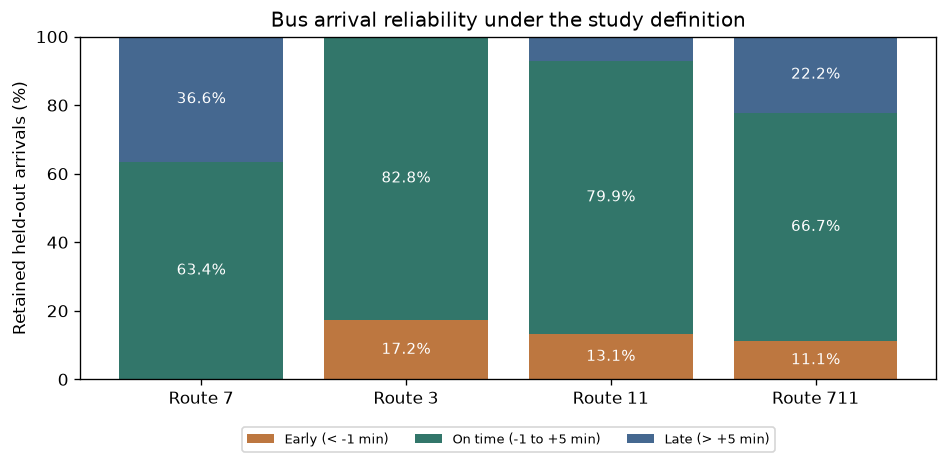

,Study window -1 to +5 min,Strict -1 to +1 min,Symmetric -2 to +2 min
route,,,
7,63.4,21.5,38.7
3,82.8,40.6,65.6
11,79.9,42.2,67.2
711,66.7,22.2,33.3


In [8]:
reliability_labels = pd.concat([result["test"] for result in route_data.values()],ignore_index=True)
reliability_labels["early"] = reliability_labels.delay_minutes.lt(-1)
reliability_labels["on_time"] = reliability_labels.delay_minutes.between(-1,5,inclusive="both")
reliability_labels["late"] = reliability_labels.delay_minutes.gt(5)
assert reliability_labels[["early","on_time","late"]].sum(axis=1).eq(1).all()
reliability = reliability_labels.groupby("route").agg(arrivals=("source_row","size"),days=("service_date","nunique"),
    early_count=("early","sum"),on_time_count=("on_time","sum"),late_count=("late","sum"),median_delay=("delay_minutes","median"))
for category in ["early","on_time","late"]:
    reliability[category+"_pct"] = 100*reliability[category+"_count"]/reliability.arrivals
reliability = reliability.reindex(ROUTES)
display(reliability[["arrivals","days","early_pct","on_time_pct","late_pct","median_delay"]].round(2))
fig,ax = plt.subplots(figsize=(8,4));x=np.arange(len(reliability));bottom=np.zeros(len(reliability))
for category,label,color in [("early","Early (< -1 min)","#bd7740"),("on_time","On time (-1 to +5 min)","#32766a"),("late","Late (> +5 min)","#456890")]:
    values = reliability[category+"_pct"].to_numpy()
    ax.bar(x,values,bottom=bottom,label=label,color=color)
    for i,(value,base) in enumerate(zip(values,bottom)):
        if value>=9:ax.text(i,base+value/2,f"{value:.1f}%",ha="center",va="center",fontsize=9,color="white")
    bottom+=values
ax.set_xticks(x,["Route "+r for r in reliability.index])
ax.set(ylabel="Retained held-out arrivals (%)",ylim=(0,100),title="Bus arrival reliability under the study definition")
ax.legend(fontsize=8,loc="upper center",bbox_to_anchor=(.5,-.12),ncol=3)
fig.tight_layout();plt.show()

sensitivity = pd.DataFrame({"Study window -1 to +5 min":reliability.on_time_pct})
for name,lower,upper in [("Strict -1 to +1 min",-1,1),("Symmetric -2 to +2 min",-2,2)]:
    sensitivity[name] = reliability_labels.assign(in_window=reliability_labels.delay_minutes.between(lower,upper)).groupby("route").in_window.mean()*100
display(sensitivity.round(1))

## 8. Consolidate the pooled experiment from Notebook 8

Notebook 8 contains the executed pooled and route-exclusion experiments. The following is a **recorded-results summary**, not a new fit or a new untouched evaluation. The measured records are embedded so this closing notebook needs no extra results file. Original-source hashes are checked before using them.

For known routes, compare the fixed separate forests with the single equal-route-weight pooled forest. This is different from choosing the lowest-validation-MAE approach separately for each route. The pooled experiment is exploratory because these evaluation outcomes had already been inspected.

For the route-exclusion experiment, training excludes the target route and uses only earlier source-route development dates. The same physical stop IDs are nevertheless represented on other routes, so this is not a test of completely new geography.

In [9]:
# Recorded measurements from the completed Notebook 8 experiment; not fabricated predictions.
RECORDED_EXTENSION = json.loads(r'''{
  "source_hashes": {
    "RTS_Route7_March2023.xlsx": "a942c3a00a6e97d887b0e7e12322b3daac5859efc7c6ad6337b9d34cc43b9585",
    "RTS_Route3_Spring2023.xlsx": "edbba91393e978b058de2b6e3c70870231f21589735cd2fcc5f1dd75ba2deef7",
    "RTS_Route11_Spring2023.xlsx": "6d19d487ee348229cfc3435d8d8d6954dec62fc0b8d26190750eb2109a50a90a",
    "RTS_Route711_Spring2023.xlsx": "3215bbd1517f0d318587d2ef349ab56e92f489a735003cc6388b0a0acd819c8c",
    "RTS_GTFS_Spring2023.zip": "1f07bd37bf6349905649b1f09a07226cc70271d2e5847ca36869270a610ac89c"
  },
  "known": [
    {
      "route": "7",
      "method": "Published schedule",
      "arrivals": 93,
      "MAE_minutes": 4.01989247311828,
      "RMSE_minutes": 5.193792533795504,
      "R2": -1.4321080146573593,
      "within_2_minutes_pct": 38.70967741935484
    },
    {
      "route": "7",
      "method": "Route development median",
      "arrivals": 93,
      "MAE_minutes": 2.7056451612903225,
      "RMSE_minutes": 3.636538510138841,
      "R2": -0.19231235836062788,
      "within_2_minutes_pct": 53.76344086021505
    },
    {
      "route": "7",
      "method": "Separate forest",
      "arrivals": 93,
      "MAE_minutes": 2.0201688322035616,
      "RMSE_minutes": 3.057042986158826,
      "R2": 0.15740911925704093,
      "within_2_minutes_pct": 63.44086021505376
    },
    {
      "route": "7",
      "method": "Pooled forest",
      "arrivals": 93,
      "MAE_minutes": 2.0246563342750914,
      "RMSE_minutes": 3.0752923355831028,
      "R2": 0.1473192173364799,
      "within_2_minutes_pct": 64.51612903225806
    },
    {
      "route": "3",
      "method": "Published schedule",
      "arrivals": 64,
      "MAE_minutes": 1.6294270833333333,
      "RMSE_minutes": 2.058266910196807,
      "R2": -0.2210691619519105,
      "within_2_minutes_pct": 65.625
    },
    {
      "route": "3",
      "method": "Route development median",
      "arrivals": 64,
      "MAE_minutes": 1.6315104166666665,
      "RMSE_minutes": 1.9180260125249142,
      "R2": -0.06034175723080493,
      "within_2_minutes_pct": 65.625
    },
    {
      "route": "3",
      "method": "Separate forest",
      "arrivals": 64,
      "MAE_minutes": 1.7723224550601637,
      "RMSE_minutes": 2.202900984038263,
      "R2": -0.3987072720769367,
      "within_2_minutes_pct": 57.8125
    },
    {
      "route": "3",
      "method": "Pooled forest",
      "arrivals": 64,
      "MAE_minutes": 1.7497496932954335,
      "RMSE_minutes": 2.0736681805324593,
      "R2": -0.23941117142900903,
      "within_2_minutes_pct": 59.375
    },
    {
      "route": "11",
      "method": "Published schedule",
      "arrivals": 244,
      "MAE_minutes": 1.7987704918032785,
      "RMSE_minutes": 2.4383365175212375,
      "R2": -0.20865706217635704,
      "within_2_minutes_pct": 67.21311475409836
    },
    {
      "route": "11",
      "method": "Route development median",
      "arrivals": 244,
      "MAE_minutes": 1.6166666666666667,
      "RMSE_minutes": 2.219011968551678,
      "R2": -0.0010023511294634524,
      "within_2_minutes_pct": 72.1311475409836
    },
    {
      "route": "11",
      "method": "Separate forest",
      "arrivals": 244,
      "MAE_minutes": 1.4402207889029186,
      "RMSE_minutes": 1.8009907611794929,
      "R2": 0.34061543310899745,
      "within_2_minutes_pct": 75.81967213114754
    },
    {
      "route": "11",
      "method": "Pooled forest",
      "arrivals": 244,
      "MAE_minutes": 1.6373606723333778,
      "RMSE_minutes": 2.205067977339211,
      "R2": 0.011538467153810017,
      "within_2_minutes_pct": 70.08196721311475
    },
    {
      "route": "711",
      "method": "Published schedule",
      "arrivals": 9,
      "MAE_minutes": 3.214814814814815,
      "RMSE_minutes": 4.26044830423823,
      "R2": -0.8390841260608792,
      "within_2_minutes_pct": 33.33333333333333
    },
    {
      "route": "711",
      "method": "Route development median",
      "arrivals": 9,
      "MAE_minutes": 2.387962962962963,
      "RMSE_minutes": 3.2384850615414544,
      "R2": -0.06261218580157757,
      "within_2_minutes_pct": 55.55555555555556
    },
    {
      "route": "711",
      "method": "Separate forest",
      "arrivals": 9,
      "MAE_minutes": 2.695569396036638,
      "RMSE_minutes": 3.640903535766344,
      "R2": -0.34310306783649547,
      "within_2_minutes_pct": 55.55555555555556
    },
    {
      "route": "711",
      "method": "Pooled forest",
      "arrivals": 9,
      "MAE_minutes": 2.9245896220064487,
      "RMSE_minutes": 3.772620257506903,
      "R2": -0.4420395797080112,
      "within_2_minutes_pct": 33.33333333333333
    }
  ],
  "transfer": [
    {
      "route": "7",
      "method": "Published schedule",
      "arrivals": 93,
      "MAE_minutes": 4.01989247311828,
      "RMSE_minutes": 5.193792533795504,
      "R2": -1.4321080146573593,
      "within_2_minutes_pct": 38.70967741935484
    },
    {
      "route": "7",
      "method": "Source-route median",
      "arrivals": 93,
      "MAE_minutes": 3.0964157706093185,
      "RMSE_minutes": 4.352407016115417,
      "R2": -0.7079402242344366,
      "within_2_minutes_pct": 48.38709677419355
    },
    {
      "route": "7",
      "method": "Route-held-out forest",
      "arrivals": 93,
      "MAE_minutes": 3.607555619823571,
      "RMSE_minutes": 4.814587319043317,
      "R2": -1.0899302818446803,
      "within_2_minutes_pct": 43.01075268817204
    },
    {
      "route": "3",
      "method": "Published schedule",
      "arrivals": 64,
      "MAE_minutes": 1.6294270833333333,
      "RMSE_minutes": 2.058266910196807,
      "R2": -0.2210691619519105,
      "within_2_minutes_pct": 65.625
    },
    {
      "route": "3",
      "method": "Source-route median",
      "arrivals": 64,
      "MAE_minutes": 1.6736979166666668,
      "RMSE_minutes": 1.959231841748756,
      "R2": -0.10639075915938467,
      "within_2_minutes_pct": 62.5
    },
    {
      "route": "3",
      "method": "Route-held-out forest",
      "arrivals": 64,
      "MAE_minutes": 3.153602635167748,
      "RMSE_minutes": 3.6525064951677972,
      "R2": -2.845199461293011,
      "within_2_minutes_pct": 31.25
    },
    {
      "route": "11",
      "method": "Published schedule",
      "arrivals": 244,
      "MAE_minutes": 1.7987704918032785,
      "RMSE_minutes": 2.4383365175212375,
      "R2": -0.20865706217635704,
      "within_2_minutes_pct": 67.21311475409836
    },
    {
      "route": "11",
      "method": "Source-route median",
      "arrivals": 244,
      "MAE_minutes": 2.002322404371585,
      "RMSE_minutes": 2.4772788077725485,
      "R2": -0.24757189662023404,
      "within_2_minutes_pct": 59.83606557377049
    },
    {
      "route": "11",
      "method": "Route-held-out forest",
      "arrivals": 244,
      "MAE_minutes": 2.4635276166236135,
      "RMSE_minutes": 2.9244644438984544,
      "R2": -0.738635325010057,
      "within_2_minutes_pct": 44.67213114754098
    },
    {
      "route": "711",
      "method": "Published schedule",
      "arrivals": 9,
      "MAE_minutes": 3.214814814814815,
      "RMSE_minutes": 4.26044830423823,
      "R2": -0.8390841260608792,
      "within_2_minutes_pct": 33.33333333333333
    },
    {
      "route": "711",
      "method": "Source-route median",
      "arrivals": 9,
      "MAE_minutes": 2.607407407407407,
      "RMSE_minutes": 3.457778848900148,
      "R2": -0.21139401217079157,
      "within_2_minutes_pct": 55.55555555555556
    },
    {
      "route": "711",
      "method": "Route-held-out forest",
      "arrivals": 9,
      "MAE_minutes": 2.1977454023830396,
      "RMSE_minutes": 3.3016821628724857,
      "R2": -0.10448932519661192,
      "within_2_minutes_pct": 66.66666666666666
    }
  ]
}''')
assert source_hashes == RECORDED_EXTENSION["source_hashes"], "Recorded extension results belong to different input files."
pooled_recorded = pd.DataFrame(RECORDED_EXTENSION["known"])
transfer_recorded = pd.DataFrame(RECORDED_EXTENSION["transfer"])
for route in ROUTES:
    original = primary_results.loc[primary_results.route.eq(route)].iloc[0]
    recorded_separate = pooled_recorded.loc[pooled_recorded.route.eq(route)&pooled_recorded.method.eq("Separate forest")].iloc[0]
    assert abs(original.MAE_minutes-recorded_separate.MAE_minutes)<1e-8
    assert original.test_labels==recorded_separate.arrivals
pooled_summary = pooled_recorded.loc[pooled_recorded.method.eq("Pooled forest")].copy()
pooled_summary["timetable_MAE_minutes"] = pooled_summary.route.map(schedule_mae)
pooled_summary["average_error_reduced_seconds"] = 60*(pooled_summary.timetable_MAE_minutes-pooled_summary.MAE_minutes)
pooled_summary["MAE_reduction_vs_timetable_pct"] = 100*(1-pooled_summary.MAE_minutes/pooled_summary.timetable_MAE_minutes)
display(pooled_summary[["route","arrivals","MAE_minutes","RMSE_minutes","within_2_minutes_pct","R2","average_error_reduced_seconds","MAE_reduction_vs_timetable_pct"]]
        .rename(columns={"route":"Route","arrivals":"Test n","MAE_minutes":"Pooled MAE (min)","RMSE_minutes":"Pooled RMSE (min)",
            "within_2_minutes_pct":"Accuracy ±2 min (%)","R2":"Test R²","average_error_reduced_seconds":"Error reduced (sec)",
            "MAE_reduction_vs_timetable_pct":"MAE reduction (%)"}).round(3))
closing_model_comparison = pooled_recorded.pivot(index="route",columns="method",values="MAE_minutes").reindex(ROUTES)
display(closing_model_comparison.round(3))
print("Excluded-route transfer: different information set, so do not treat it as an equivalent competitor to a model trained on that route.")
display(transfer_recorded[["route","method","arrivals","MAE_minutes","RMSE_minutes","within_2_minutes_pct","R2"]].round(3))

Excluded-route transfer: different information set, so do not treat it as an equivalent competitor to a model trained on that route.


,Route,Test n,Pooled MAE (min),Pooled RMSE (min),Accuracy ±2 min (%),Test R²,Error reduced (sec),MAE reduction (%)
3,7,93,2.025,3.075,64.516,0.147,119.714,49.634
7,3,64,1.750,2.074,59.375,-0.239,-7.219,-7.384
11,11,244,1.637,2.205,70.082,0.012,9.685,8.973
15,711,9,2.925,3.773,33.333,-0.442,17.414,9.028


method,Pooled forest,Published schedule,Route development median,Separate forest
route,,,,
7,2.025,4.020,2.706,2.020
3,1.750,1.629,1.632,1.772
11,1.637,1.799,1.617,1.440
711,2.925,3.215,2.388,2.696


,route,method,arrivals,MAE_minutes,RMSE_minutes,within_2_minutes_pct,R2
0,7,Published schedule,93,4.020,5.194,38.710,-1.432
1,7,Source-route median,93,3.096,4.352,48.387,-0.708
2,7,Route-held-out forest,93,3.608,4.815,43.011,-1.090
3,3,Published schedule,64,1.629,2.058,65.625,-0.221
4,3,Source-route median,64,1.674,1.959,62.500,-0.106
5,3,Route-held-out forest,64,3.154,3.653,31.250,-2.845
6,11,Published schedule,244,1.799,2.438,67.213,-0.209
7,11,Source-route median,244,2.002,2.477,59.836,-0.248
8,11,Route-held-out forest,244,2.464,2.924,44.672,-0.739
9,711,Published schedule,9,3.215,4.260,33.333,-0.839


### Final interpretation of pooling

The pooled model's arrival-weighted MAE is **1.77 minutes**, versus **1.65 minutes** for the separate forests: about seven seconds more error per arrival. Their ±2-minute hit rates are **66.3%** and **69.8%**, respectively.

Pooling was effectively tied on Route 7, slightly better on Route 3, and worse on Routes 11 and 711. This is broadly comparable performance for one shared model, not a demonstrated accuracy improvement or statistical equivalence. Separate models remain the stronger current benchmark overall.

The excluded-route forest beat the timetable on two of four exclusions. All evaluated locations were already represented in training routes; operating-period differences and tiny Route 711 samples further limit transfer claims. No universal model has been established.

## 9. Final conclusions - answers for the report



**These are held-out scores with provisional labels.** The date holdout is real, but the linkage evidence is not independently confirmed. Do not describe this as verified RTS-wide accuracy.



### Route 7

Fit on **304 development labels** and evaluated **93 held-out arrivals across 4 day(s)**. Timetable MAE **4.020 minutes**, development median **2.706**, frozen forest **2.020**.

The forest changes MAE relative to the timetable by **49.7% toward lower error**; a negative number means worse. **63.4%** of forest predictions are within two minutes of the retained actual arrivals. This is not a claim about unmatched visits.



### Route 3

Fit on **196 development labels** and evaluated **64 held-out arrivals across 4 day(s)**. Timetable MAE **1.629 minutes**, development median **1.632**, frozen forest **1.772**.

The forest changes MAE relative to the timetable by **-8.8% toward lower error**; a negative number means worse. **57.8%** of forest predictions are within two minutes of the retained actual arrivals. This is not a claim about unmatched visits.



### Route 11

Fit on **781 development labels** and evaluated **244 held-out arrivals across 4 day(s)**. Timetable MAE **1.799 minutes**, development median **1.617**, frozen forest **1.440**.

The forest changes MAE relative to the timetable by **19.9% toward lower error**; a negative number means worse. **75.8%** of forest predictions are within two minutes of the retained actual arrivals. This is not a claim about unmatched visits.



### Route 711

Fit on **110 development labels** and evaluated **9 held-out arrivals across 1 day(s)**. Timetable MAE **3.215 minutes**, development median **2.388**, frozen forest **2.696**.

The forest changes MAE relative to the timetable by **16.2% toward lower error**; a negative number means worse. **55.6%** of forest predictions are within two minutes of the retained actual arrivals. This is not a claim about unmatched visits.



### Did the fixed model generalize?

The frozen forest beats the timetable on **3 of 4 routes**, and beats the development median on **2 of 4 routes**. Report all four results, including losses. This evaluates separate route-specific models, not transfer of one fitted model to an unseen route.

Equal-route-weight forest MAE is **1.982 minutes**; equal-arrival-weight MAE is **1.651 minutes**. Different values reflect unequal sample counts. Neither estimates the whole RTS system.



### What does a baseline win mean?

A historical median can be a strong operational benchmark. A loss by a forest is a finding, not a reason to tune again on these same held-out dates. If a new model is developed afterward, obtain a new independent evaluation period or clearly label subsequent analysis exploratory.



### Did we verify the labels?

We reproduced existing development counts, checked ordered patterns and other anchors, preserved exclusions, and created a source-traceable review ledger. These checks do not independently validate the trip assignments. The ledger remains marked unconfirmed. Before claiming verified arrival-delay performance, resolve the historical schedule/trip evidence and document reviewer decisions. A small reviewed sample alone cannot certify all labels.



### What was protected against look-ahead?

Procedure choices were frozen before scoring. Encoders and forests were fitted only on eligible development dates; medians use development outcomes only. No held-out errors chose predictors, tuning strengths, model settings, or outlier rules. Retrospective schedule evidence constructs provisional labels, so the matcher itself is not claimed available in real time.



### Why can we not claim system-wide generalization?

Routes overlap geographically; time periods and stop scopes differ; Route 711 has only one reserved day; labels and inclusion rules are inferred; and only explicitly timed retained visits are evaluated. Many repeated arrivals do not replace independent operating days.



### Is the undergraduate modeling exercise complete?

The reproducible development-to-held-out modeling sequence is complete as an exploratory exercise. The report should state the target, source/coverage, frozen choices, baselines, per-route errors, failures, and unresolved label verification. Independent confirmation is still required for a stronger factual performance claim.



### What did the pooled extension establish?

Notebook 8 completed the exploratory pooled and route-exclusion experiments. One shared model performed broadly comparably, with some loss relative to separate fits; transfer was inconsistent. This is enough to discuss generalization limits in the final report. Any later refinements belong in future work with new independent evaluation data.



### Suggested report structure

1. Research question: arrival delay relative to the published timetable.
2. Data and modeling scope for each route.
3. Cleaning, provisional schedule assignment, and exclusion counts.
4. Chronological development selection and frozen procedures.
5. Held-out results and baseline comparisons, including failures.
6. Label uncertainty, limited days, selection bias, and future work.



**Sources:** Richard Borzi / University of Florida; data supplied by Gainesville RTS, CC BY 4.0. [Route 7](https://zenodo.org/records/10034933), [Route 3](https://zenodo.org/records/10034688), [Route 11](https://zenodo.org/records/10034723), [Route 711](https://zenodo.org/records/10034622). Historical [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0).
### Why do these numbers differ from the earlier notebooks?

Earlier notebooks evaluated validation dates using fits on the earlier training period. Here the fixed procedures are refitted on all eligible development dates and evaluated on different, later reserved dates. This is not a before/after comparison on identical observations. It is normal for model rankings and error levels to change, and Route 3's loss illustrates why a validation winner is not guaranteed to win later.

### Suggested final conclusion

Within the retained, provisionally matched timepoints, separately fitted frozen forests improved on the published timetable for three of four routes. They improved on a development-period median for two routes. Benefits varied by route and operating day; a simple baseline sometimes performed better. Because schedule links remain unconfirmed, selection excludes uncertain visits, routes and dates are not independent system-wide samples, and Route 711 has only nine test arrivals on one day, this is exploratory evidence rather than verified RTS-wide arrival accuracy.


## Optional - save the tables and review worksheet

The plan file was saved before evaluation. Uncomment these lines to save results and a review ledger beside the notebook. Do not change an independent-review status without documenting the evidence. These are new outputs; raw files remain unchanged.

In [10]:
# test_results.to_csv("RTS_Provisional_Heldout_Results.csv",index=False)
# coverage.to_csv("RTS_Label_Coverage.csv",index=False)
# test_predictions.to_csv("RTS_Heldout_Predictions.csv",index=False)
# review_ledger.to_csv("RTS_Label_Review_Ledger.csv",index=False)
# reliability.to_csv("RTS_Arrival_Reliability.csv")
# pooled_summary.to_csv("RTS_Pooled_Results_Summary.csv",index=False)

## Project close: what to submit and say

Submit Notebooks 5–9, the original source files with attribution, the LaTeX report, and the selected figures. Keep the same-folder input filenames or document the repository's paths. Raw workbooks remain unchanged.

**One-paragraph conclusion:** “Using historical RTS observations and inferred schedule assignments, we built arrival-delay baselines and route-specific predictors. The fixed forests improved on the timetable for three of four routes, but simple medians remained competitive. A shared pooled model performed broadly comparably, with some loss relative to separate fits; transfer to excluded routes was inconsistent. Our conclusions apply to retained timepoints and a small set of operating dates, rather than verified system-wide or live-app accuracy.”

Explain separately that **bus reliability** means how close recorded arrivals were to schedule, while **prediction accuracy** means how close predictions were to recorded arrivals. Include sample counts, the chosen on-time window, the inferred-match assumption, and failures as well as successes.

This is the end of the project analysis. Further independent data, label confirmation, or pooling refinements belong in future work, not additional required notebook tasks.